# 问题1：冻结模型复现、缺失敏感性与相对分级

这是结果复查Notebook，不是完整训练流程。完整计算入口为 scripts/run_review.py。

In [1]:
from pathlib import Path
import os
import pandas as pd
from IPython.display import display, Image
OUT=next((p for p in [Path.cwd(),*Path.cwd().parents] if (p/'q1_metrics.csv').is_file()), None)
if OUT is None:
    ROOT=next((p for p in [Path.cwd(),*Path.cwd().parents] if (p/'scripts/run_review.py').is_file()), None)
    if ROOT is None: raise FileNotFoundError('请从项目目录或输出目录启动Notebook')
    OUT=Path(os.environ.get('MATHORCUP_OUTPUT',str(ROOT/'results' if (ROOT/'results').is_dir() else ROOT/'outputs/competition_candidate_v3')))
pd.set_option('display.max_rows',160)
pd.set_option('display.max_columns',25)

## 注意

本笔记本读取新生成的独立结果。真实原始0–6分逆变换仍不可识别；所有等级列都是训练集分位数相对等级。训练OOF成绩并非无偏的嵌套选模估计，因为候选选择曾使用同一训练集CV。

In [2]:
m=pd.read_csv(OUT/'q1_metrics.csv'); display(m.groupby('split').mean(numeric_only=True)); display(pd.read_csv(OUT/'q1_train_quantile_cutpoints.csv')); display(pd.read_csv(OUT/'q1_missingness_sensitivity.csv').groupby('additional_missing_rate').MAE.agg(['mean','std'])); display(pd.read_csv(OUT/'barcode_precision_audit.csv').head())

,MAE,baseline_MAE,R2,relative_grade_MAE,relative_baseline_grade_MAE,relative_grade_accuracy,interval_coverage
split,,,,,,,
heldout_test,0.338000,0.412026,0.231425,1.542,1.8420,0.2044,0.9056
training_oof,0.344239,0.418768,0.230605,1.574,1.8757,0.2074,0.9050


,target,q1,q2,q3,q4,q5,q6,distinct_cutpoints
0,A_malt_all,-0.648047,-0.476551,-0.240906,-0.032720,0.374111,0.726371,6
1,A_malt_grain,-0.404612,-0.252799,-0.137826,-0.023328,0.148156,0.459463,6
2,A_malt_bread,-0.407046,-0.268522,-0.175355,-0.026429,0.177855,0.518452,6
3,A_malt_cara,-0.528486,-0.435965,-0.255208,-0.086833,0.164678,0.619333,6
4,A_malt_burn,-0.371750,-0.342727,-0.271850,-0.144531,-0.035766,0.336798,6
5,A_hops_all,-0.666533,-0.425133,-0.177721,0.059149,0.251048,0.689121,6
6,A_hops_citrus,-0.426447,-0.361909,-0.236278,-0.087456,0.131450,0.445255,6
7,A_hops_tropical,-0.395672,-0.359363,-0.245609,-0.113051,0.076286,0.274847,6
8,A_hops_noble,-0.565742,-0.308389,-0.160046,0.052056,0.229309,0.597225,6
9,A_hops_woody,-0.337560,-0.279721,-0.184376,-0.074348,0.104515,0.354692,6


,mean,std
additional_missing_rate,,
0.00,0.338000,0.000000
0.05,0.338484,0.001309
0.10,0.339605,0.001416
0.20,0.341439,0.001548


,beer,a1_beer_id,a4_beer_id,exact_equal,relative_difference
0,1,5413970150111,5.413970e+12,False,2.772660e-08
1,2,5410228142003,5.410230e+12,False,3.434230e-07
2,3,54055308,5.405531e+07,True,0.000000e+00
3,4,54079021,5.407902e+07,True,0.000000e+00
4,5,5400000000006,5.400000e+12,False,1.111111e-12


,beer,target,split,model,actual_standardized,predicted_standardized,baseline_standardized,actual_relative_grade,predicted_relative_grade,baseline_relative_grade,lower_descriptive,upper_descriptive
0,147,A_malt_all,training_oof,岭回归,-0.634319,-0.343325,0.022265,1,2,4,-1.190664,0.504015
1,73,A_malt_all,training_oof,岭回归,-0.816181,-0.710112,-0.021154,0,0,4,-1.557451,0.137227
2,230,A_malt_all,training_oof,岭回归,-0.639861,-0.497148,0.022265,1,1,4,-1.344487,0.350191
3,15,A_malt_all,training_oof,岭回归,0.669493,0.171068,0.021567,5,4,4,-0.676271,1.018408
4,41,A_malt_all,training_oof,岭回归,-0.011527,-0.237334,0.022265,4,3,4,-1.084673,0.610005
5,131,A_malt_all,training_oof,岭回归,0.798208,0.554889,0.028890,6,5,4,-0.292451,1.402228
6,72,A_malt_all,training_oof,岭回归,-0.647606,0.074375,0.022265,0,4,4,-0.772965,0.921714
7,207,A_malt_all,training_oof,岭回归,-1.019600,-0.562139,0.021567,0,1,4,-1.409479,0.285200
8,48,A_malt_all,training_oof,岭回归,0.032673,0.830292,0.021567,4,6,4,-0.017047,1.677631
9,209,A_malt_all,training_oof,岭回归,-0.681372,-0.068358,-0.022095,0,3,4,-0.915697,0.778981


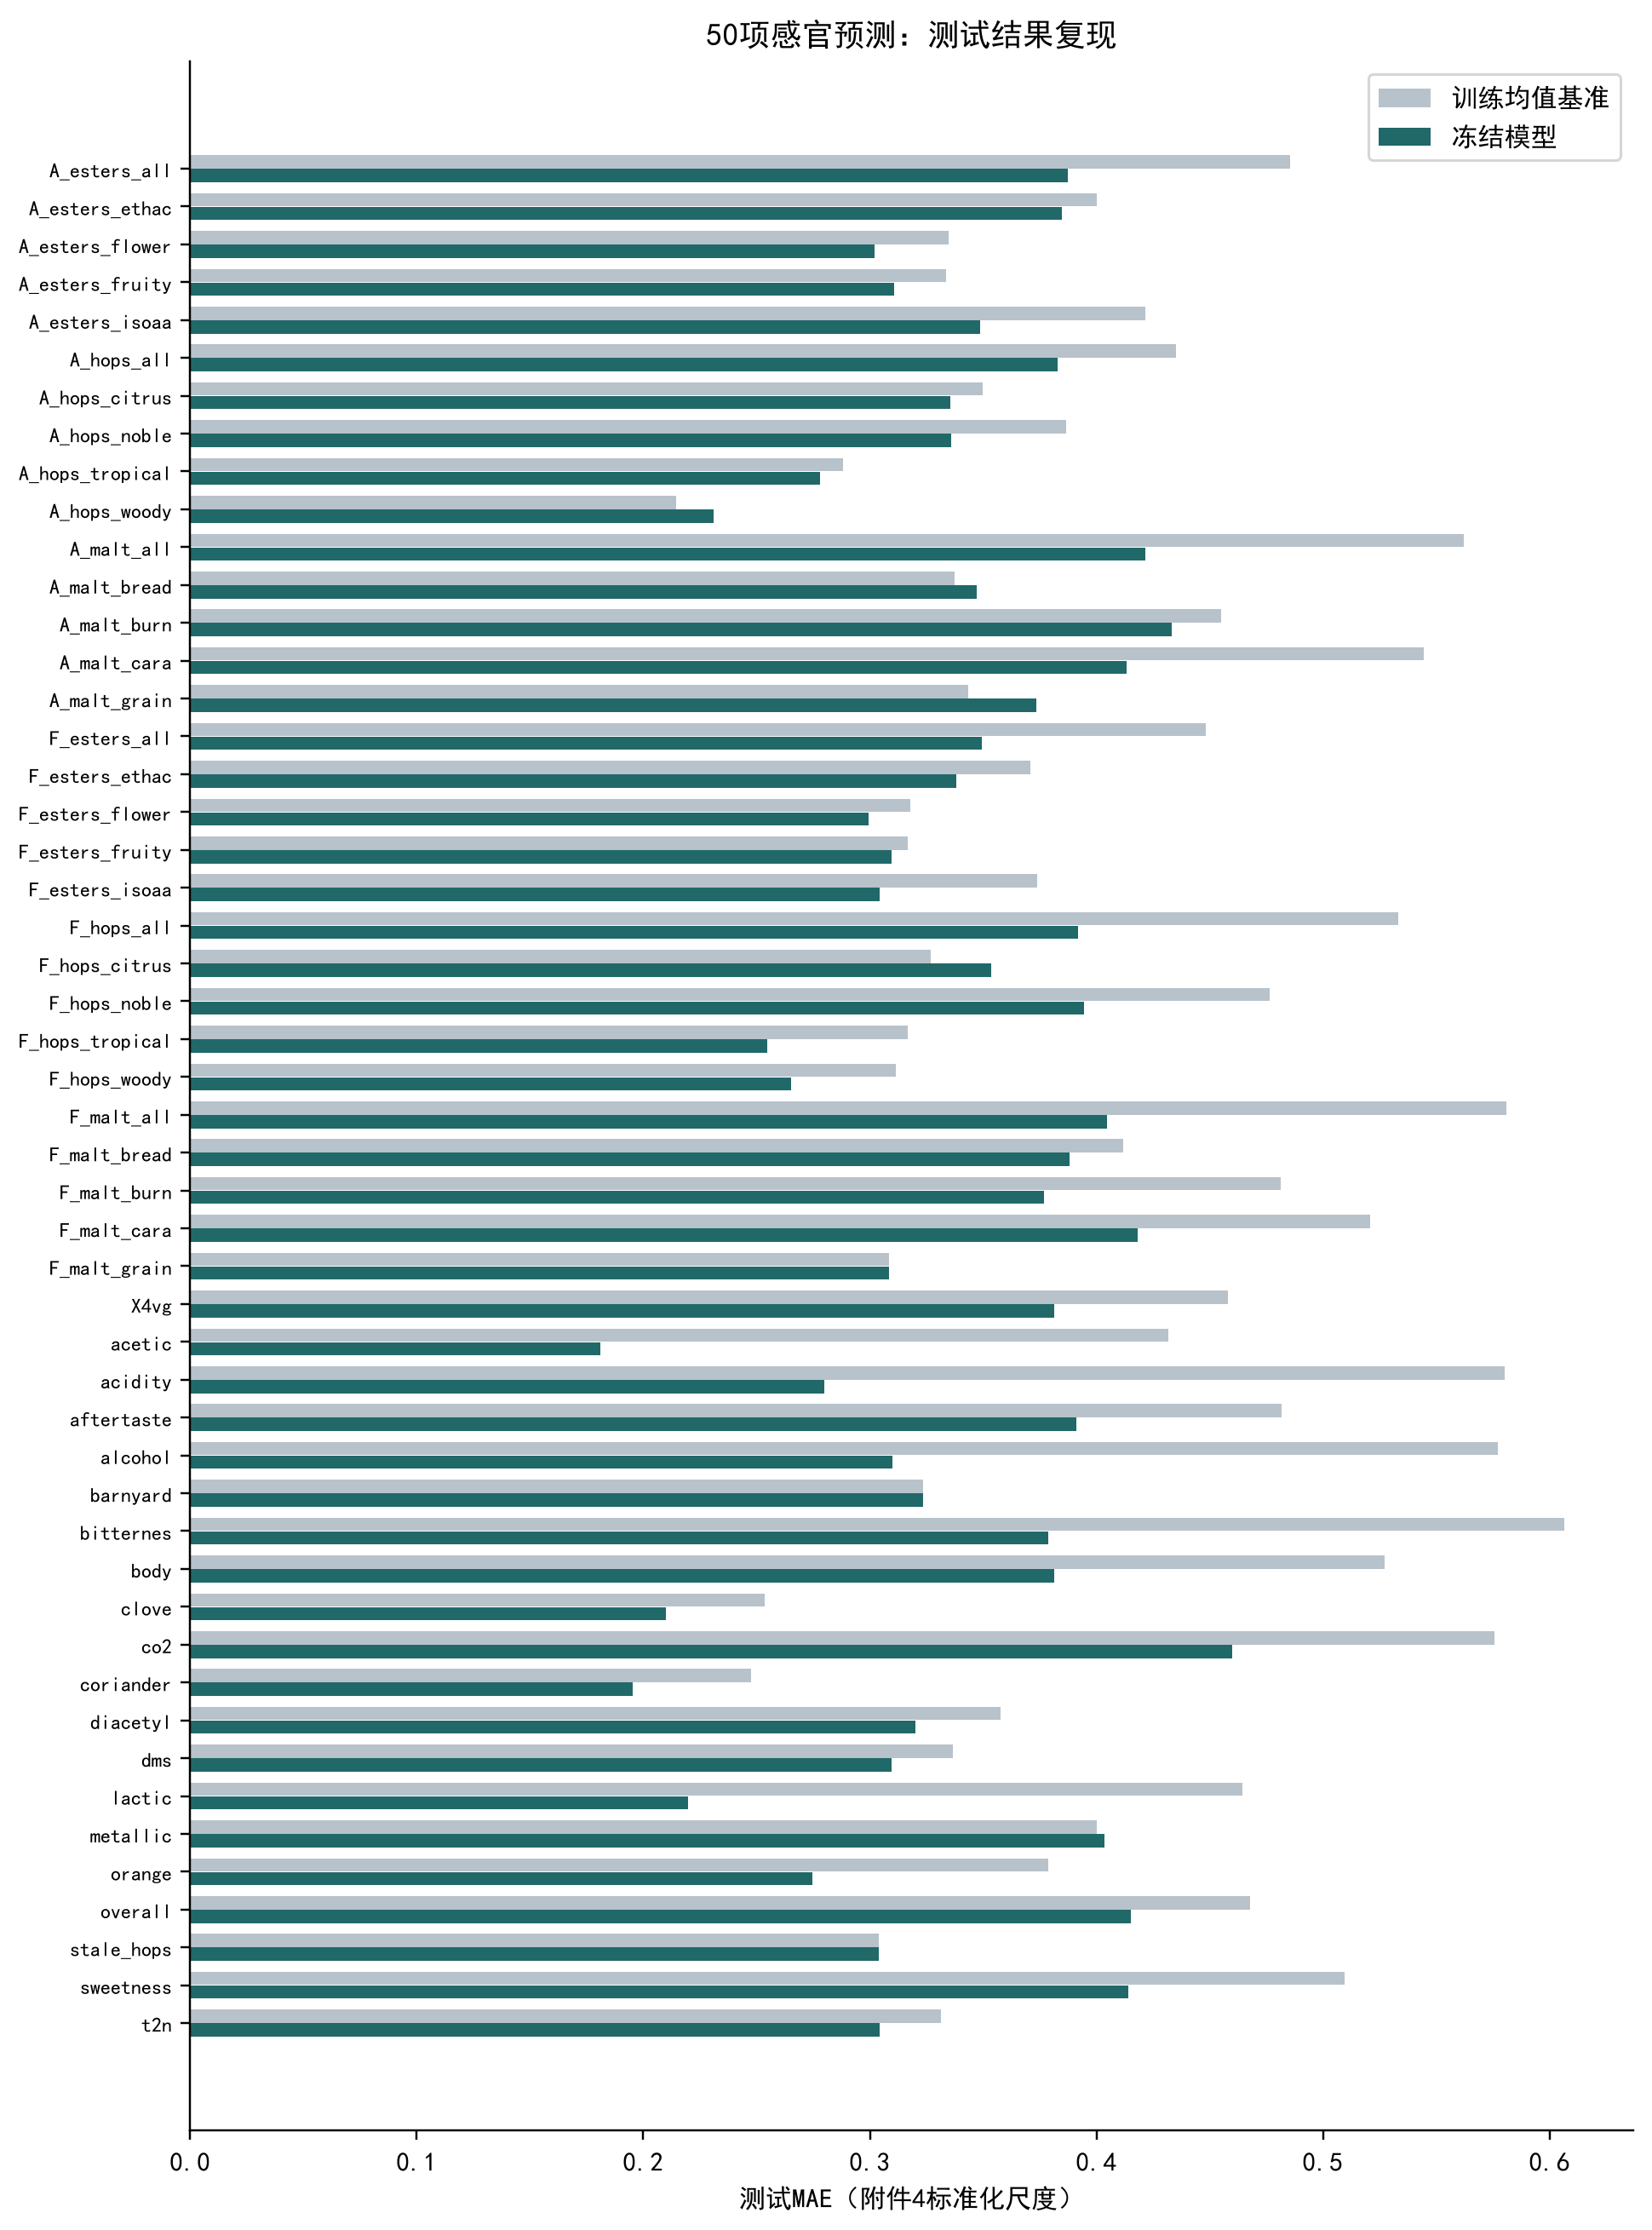

In [3]:
p=pd.read_csv(OUT/'q1_out_of_sample_predictions.csv'); assert len(p)==12500; assert not p.duplicated(['beer','target']).any(); display(p.head(20)); display(Image(filename=str(OUT/'figures/01_prediction_errors.png')))

In [4]:
display(pd.read_csv(OUT/'q1_group_metrics.csv')); comparison=pd.read_csv(OUT/'q1_dimension_comparison.csv');display(comparison.loc[comparison.comparison.ne('better')])

,split,group,n_targets,n_beers,baseline_MAE,model_MAE,improvement_pct,baseline_grade_MAE,model_grade_MAE,baseline_grade_accuracy,model_grade_accuracy
0,training_oof,Aroma,15,200,0.410194,0.365011,11.015000,1.845333,1.586000,0.148000,0.197667
1,training_oof,Flavour,15,200,0.417349,0.356607,14.554213,1.818667,1.527667,0.147000,0.203333
2,training_oof,All50,50,200,0.418768,0.344239,17.797337,1.875700,1.574000,0.146100,0.207400
3,heldout_test,Aroma,15,50,0.392874,0.352359,10.312336,1.722667,1.529333,0.177333,0.181333
4,heldout_test,Flavour,15,50,0.406366,0.343816,15.392567,1.794667,1.493333,0.160000,0.210667
5,heldout_test,All50,50,50,0.412026,0.338000,17.966406,1.842000,1.542000,0.158000,0.204400


,target,split,MAE,baseline_MAE,R2,relative_grade_MAE,relative_baseline_grade_MAE,relative_grade_accuracy,interval_coverage,mae_improvement_pct,comparison
0,A_malt_grain,heldout_test,0.373485,0.343515,-0.208864,1.86,1.74,0.10,0.92,-8.724570,worse
1,F_hops_citrus,heldout_test,0.353380,0.326747,-0.335850,1.96,2.00,0.18,0.88,-8.150892,worse
2,A_hops_woody,heldout_test,0.231065,0.214388,-0.251627,1.44,1.44,0.24,0.90,-7.779020,worse
3,A_malt_bread,heldout_test,0.347041,0.337539,-0.057952,1.56,1.52,0.20,0.92,-2.814891,worse
4,metallic,heldout_test,0.403491,0.399989,-0.061521,1.94,2.08,0.16,0.82,-0.875349,worse
5,F_malt_grain,heldout_test,0.308623,0.308623,-0.005913,1.50,1.50,0.20,0.92,0.000000,equal
6,stale_hops,heldout_test,0.304087,0.304087,-0.006460,1.76,1.76,0.16,0.82,0.000000,equal
7,barnyard,heldout_test,0.323330,0.323330,-0.004441,1.90,1.90,0.10,0.84,0.000000,equal
